In [20]:
import numpy as np

from math import sqrt



import matplotlib
import matplotlib.pyplot as plt
import os

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42




# Changing the number of dimensions d

In [21]:
x_num = 'x0'
path = f"../results/grad_accuracy/changing_d"
os.makedirs(f"{path}/img", exist_ok=True)
dims = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 20, 30, 50, 100, 500, 600, 1000]
methods = ['FFD_G', 'FFD_SP', 'FFD_CO', 'FFD_QR', 'CFD_G', 'CFD_SP', 'CFD_CO', 'CFD_QR', 'GGA_G', 'GGA_SP', 'GGA_CO', 'GGA_QR', 'CGGA_G', 'CGGA_SP', 'CGGA_CO', 'CGGA_QR', 'LI_G', 'LI_SP', 'LI_CO', 'LI_QR', 'CLI_G', 'CLI_SP', 'CLI_CO', 'CLI_QR', 'GSGA_CO', 'CGSGA_CO', 'GSGA_QR', 'CGSGA_QR']


In [22]:
fun = "Sphere"
results = {}
c = 0
# Load results
for d in dims:
    results[d] = {}
    with open(f"{path}/{fun}_{d}_{d}.log", 'r') as f:
        lines = f.readlines()
        for line in lines:
            if '[++]' in line:
                results[d][c] = {}
                c += 1
            else:
                spl = line.strip().split(",")
                results[d][c - 1][spl[0]] = (float(spl[1]), float(spl[2]), float(spl[3]), float(spl[4]))
        c= 0
                                

In [23]:
def plot_result(title, res, out, reps=200):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
#    ax1.set_title(title, fontsize=20)
    fig.suptitle(title, fontsize=20)
    labels= []
    acc_data = []
    tm_data = []
    c = 0
    str_tb = "Approximation & Relative Error & Time Cost\n"
    cmap = matplotlib.colormaps['gist_rainbow']

    norm = matplotlib.colors.Normalize(vmin=0.0, vmax=len(res.items()))
    for (i, (k, v)) in enumerate(res.items()):
        if 'CLI' in k:
            continue
        labels.append(k.replace("_",'-'))
        acc_data.append(( v[0], v[1]))
        tm_data.append((v[2], v[3]))
#        print(norm(i))
        ax1.bar(c, v[0], facecolor=cmap(c/24))
        ax2.bar(c, v[2], facecolor=cmap(c/24))
        c += 1
        str_tb += f"{labels[-1]} & {v[0]} \pm {v[1]} & {v[2]} \pm {v[3]}\\\\\n"
#    ax1.boxplot(acc_data, positions=[i + 5 for i in range(len(acc_data))])
    
#    ax1.errorbar([i + 5 for i in range(len(means))], means, fmt='o', yerr=stds)
    ax1.set_xticks([i for i in range(len(labels))], labels, rotation='vertical')
    ax1.set_yscale("log")
    ax1.set_ylabel("$\\frac{\\| \\nabla f(x) - g(x) \\|}{\\| \\nabla f(x) \\|}$", fontsize=18)
#    ax2.boxplot(tm_data, positions=[i + 5 for i in range(len(tm_data))])
#    ax2.errorbar([i + 5 for i in range(len(tm_mean))], tm_mean, fmt='o', c='red', yerr=tm_std)
    ax2.set_xticks([i for i in range(len(tm_data))], labels, rotation='vertical')
    ax2.set_yscale("log")
    ax2.set_ylabel("$s$", fontsize=18)
    fig.tight_layout()
    fig.savefig(f"{path}/img/{out}", bbox_inches='tight')
    plt.close(fig)
    with open(f"{path}/img/{out.split('.')[0]}_info.log", 'w') as f:
        f.write(str_tb + "\n")
    return labels, acc_data, tm_data
    

In [24]:
reps = 200
ov_res = {}
#tm_res = {}

omap = {}



for c in range(1):#[0, 1, 2]:
    for d in dims:
        labels, acc_data, tm_data = plot_result('Sphere d = {}'.format(d), results[d][c], 'sphere_{}_{}_{}.pdf'.format(d, d, c), reps=reps)
        print(f"[--] Plotted x_{c} with d = {d}")
        ov_res[d] = (acc_data, tm_data)
        

[--] Plotted x_0 with d = 1
[--] Plotted x_0 with d = 2
[--] Plotted x_0 with d = 3
[--] Plotted x_0 with d = 4
[--] Plotted x_0 with d = 5
[--] Plotted x_0 with d = 6
[--] Plotted x_0 with d = 7
[--] Plotted x_0 with d = 8
[--] Plotted x_0 with d = 9
[--] Plotted x_0 with d = 10
[--] Plotted x_0 with d = 20
[--] Plotted x_0 with d = 30
[--] Plotted x_0 with d = 50
[--] Plotted x_0 with d = 100
[--] Plotted x_0 with d = 500
[--] Plotted x_0 with d = 600
[--] Plotted x_0 with d = 1000


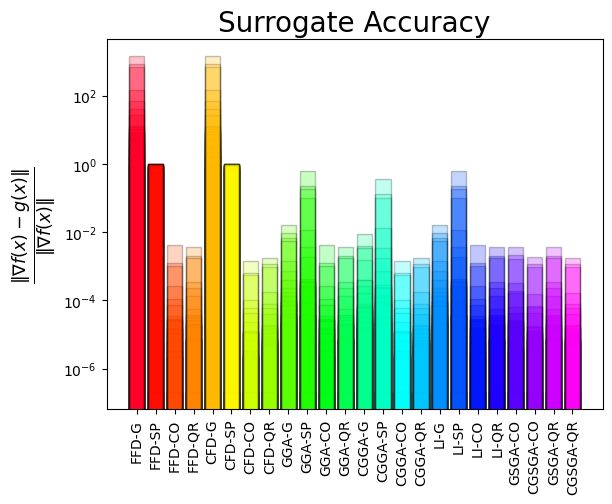

In [25]:
cmap = matplotlib.colormaps['gist_rainbow']

norm = matplotlib.colors.Normalize(vmin=0.0, vmax=len(labels))

fig, ax = plt.subplots()
for (i, d) in enumerate(dims):
    acc, tm = ov_res[d]
    for (j, v) in enumerate(acc):
#        print(v)
        ax.bar(j, v[0], facecolor=cmap(j/len(labels)), edgecolor='black', alpha=np.clip(1/np.sqrt(i + 1), 0.15, 1.0))

    
ax.set_title("Surrogate Accuracy", fontsize=20)
ax.set_xticks([i for i in range(len(labels))], labels, rotation='vertical')
ax.set_yscale("log")
ax.set_ylabel("$\\frac{\\| \\nabla f(x) - g(x) \\|}{\\| \\nabla f(x) \\|}$", fontsize=18)
fig.savefig(f"{path}/img/surrogate_accuracy_overall.pdf", bbox_inches='tight')

In [26]:
print(len(ov_res[1][0]))

24


In [27]:
for lbl in ['FFD', 'CFD', 'GGA', 'CGGA', 'LI', 'GSGA', 'CGSGA']:
    #lbl = "LI"
    ov_res_2 = {}
    idx_sub = [i for i in range(len(labels)) if labels[i].split("-")[0] == lbl]
    sub_labels = [labels[i] for i in range(len(labels)) if labels[i].split("-")[0] == lbl]

    print(sub_labels)
    for i in range(len(sub_labels)):
        if lbl not in ov_res_2:
            ov_res_2[i] = []

    for d in dims:
        d_ris = ov_res[d][0]
        for i in range(len(sub_labels)):
            ov_res_2[i].append(d_ris[idx_sub[i]])

    cmap = matplotlib.colormaps['magma']

    norm = matplotlib.colors.Normalize(vmin=0.0, vmax=len(sub_labels))

    fig, ax = plt.subplots()
    # for (i, d) in enumerate(dims):
    #     acc, tm = ov_res[d]
    #     for (j, v) in enumerate(acc):
    # #        print(v)
    #         ax.bar(j, v[0], facecolor=cmap(norm(j)), edgecolor='black', alpha=np.clip(1/np.sqrt(i + 1), 0.15, 1.0))
    for i in range(len(sub_labels)):
    #    print(ov_res_2[i].keys())
        ax.plot(range(len(ov_res_2[i])), [x[0] for x in ov_res_2[i]], 'o-', c=cmap(i/len(sub_labels)), label=sub_labels[i])

    #ax.set_title("Surrogate Accuracy changing $d$", fontsize=20)
    ax.set_xticks([i for i in range(len(dims))], dims)
    ax.legend()
    ax.set_yscale("log")
    ax.set_ylabel("$\\frac{\\| \\nabla f(x) - g(x) \\|}{\\| \\nabla f(x) \\|}$", fontsize=18)
    ax.set_xlabel("$d$", fontsize=18)
    fig.savefig(f"{path}/img/surr_acc_{lbl}.pdf", bbox_inches='tight')
    plt.close(fig)

['FFD-G', 'FFD-SP', 'FFD-CO', 'FFD-QR']
['CFD-G', 'CFD-SP', 'CFD-CO', 'CFD-QR']
['GGA-G', 'GGA-SP', 'GGA-CO', 'GGA-QR']
['CGGA-G', 'CGGA-SP', 'CGGA-CO', 'CGGA-QR']
['LI-G', 'LI-SP', 'LI-CO', 'LI-QR']
['GSGA-CO', 'GSGA-QR']
['CGSGA-CO', 'CGSGA-QR']


In [28]:
for lbl in ['FFD', 'CFD', 'GGA', 'CGGA', 'LI', 'GSGA', 'CGSGA']:
    #lbl = "LI"
    ov_res_2 = {}
    idx_sub = [i for i in range(len(labels)) if labels[i].split("-")[0] == lbl]
    sub_labels = [labels[i] for i in range(len(labels)) if labels[i].split("-")[0] == lbl]

    print(sub_labels)
    for i in range(len(sub_labels)):
        if lbl not in ov_res_2:
            ov_res_2[i] = []

    for d in dims:
        d_ris = ov_res[d][1]
        for i in range(len(sub_labels)):
            ov_res_2[i].append(d_ris[idx_sub[i]])

    cmap = matplotlib.colormaps['magma']

    norm = matplotlib.colors.Normalize(vmin=0.0, vmax=len(sub_labels))

    fig, ax = plt.subplots()
    # for (i, d) in enumerate(dims):
    #     acc, tm = ov_res[d]
    #     for (j, v) in enumerate(acc):
    # #        print(v)
    #         ax.bar(j, v[0], facecolor=cmap(norm(j)), edgecolor='black', alpha=np.clip(1/np.sqrt(i + 1), 0.15, 1.0))
    for i in range(len(sub_labels)):
    #    print(ov_res_2[i].keys())
        ax.plot(range(len(ov_res_2[i])), [x[0] for x in ov_res_2[i]], 'o-', c=cmap(i/len(sub_labels)), label=sub_labels[i])

    #ax.set_title("Surrogate Accuracy changing $d$", fontsize=20)
    ax.set_xticks([i for i in range(len(dims))], dims)
    ax.legend()
    ax.set_yscale("log")
    ax.set_ylabel("$s$", fontsize=18)
#    ax.set_ylabel("$\\frac{\\| \\nabla f(x) - g(x) \\|}{\\| \\nabla f(x) \\|}$", fontsize=18)
    ax.set_xlabel("$d$", fontsize=18)
    fig.savefig(f"{path}/img/surr_tm_{lbl}.pdf", bbox_inches='tight')
    plt.close(fig)

['FFD-G', 'FFD-SP', 'FFD-CO', 'FFD-QR']
['CFD-G', 'CFD-SP', 'CFD-CO', 'CFD-QR']
['GGA-G', 'GGA-SP', 'GGA-CO', 'GGA-QR']
['CGGA-G', 'CGGA-SP', 'CGGA-CO', 'CGGA-QR']
['LI-G', 'LI-SP', 'LI-CO', 'LI-QR']
['GSGA-CO', 'GSGA-QR']
['CGSGA-CO', 'CGSGA-QR']


# Changing l

In [29]:
path = "../results/grad_accuracy/changing_l"
d = 100
dims = [1, 5, 10, 15, 25, 50, 75, 85, 100]#[1] + [i for i in range(5, d + 5, 5)]#, 6, 7, 10, 20, 50, 100]
methods = ['FFD_G', 'FFD_SP', 'FFD_CO', 'FFD_QR', 'CFD_G', 'CFD_SP', 'CFD_CO', 'CFD_QR', 'GGA_G', 'GGA_SP', 'GGA_CO', 'GGA_QR', 'CGGA_G', 'CGGA_SP', 'CGGA_CO', 'CGGA_QR', 'LI_G', 'LI_SP', 'LI_CO', 'LI_QR', 'CLI_G', 'CLI_SP', 'CLI_CO', 'CLI_QR', 'GSGA_CO', 'CGSGA_CO', 'GSGA_QR', 'CGSGA_QR']


In [30]:
fun = "Sphere"
results = {}
c = 0
# Load results
for l in dims:
    results[l] = {}
    with open(f"{path}/{fun}_{d}_{l}.log", 'r') as f:
        lines = f.readlines()
        for line in lines:
            if '[++]' in line:
                results[l][c] = {}
                c += 1
            else:
                spl = line.strip().split(",")
                results[l][c - 1][spl[0]] = (float(spl[1]), float(spl[2]), float(spl[3]), float(spl[4]))
        c= 0
                                

In [31]:
cl_results = {}
for l in dims:
    labels, acc_data, tm_data = plot_result('Sphere d = {} l = {}'.format(d, l), results[l][0], 'sphere_{}_l{}_{}.pdf'.format(d, l, 0))
    print(f"[--] Plotted x_{0} with d = {d} l = {l}")
    cl_results[l] = (acc_data, tm_data)

[--] Plotted x_0 with d = 100 l = 1
[--] Plotted x_0 with d = 100 l = 5
[--] Plotted x_0 with d = 100 l = 10
[--] Plotted x_0 with d = 100 l = 15
[--] Plotted x_0 with d = 100 l = 25
[--] Plotted x_0 with d = 100 l = 50
[--] Plotted x_0 with d = 100 l = 75
[--] Plotted x_0 with d = 100 l = 85
[--] Plotted x_0 with d = 100 l = 100


In [32]:
for lbl in ['FFD', 'CFD', 'GGA', 'CGGA', 'GSGA', 'CGSGA']:
    #lbl = "LI"
    ov_res_2 = {}
    idx_sub = [i for i in range(len(labels)) if labels[i].split("-")[0] == lbl]
    sub_labels = [labels[i] for i in range(len(labels)) if labels[i].split("-")[0] == lbl]

    print(sub_labels)
    for i in range(len(sub_labels)):
        if lbl not in ov_res_2:
            ov_res_2[i] = []

    for d in dims:
        d_ris = cl_results[d][0]
        for i in range(len(sub_labels)):
            ov_res_2[i].append(d_ris[idx_sub[i]])

    cmap = matplotlib.colormaps['magma']

    norm = matplotlib.colors.Normalize(vmin=0.0, vmax=len(sub_labels))

    fig, ax = plt.subplots()
    # for (i, d) in enumerate(dims):
    #     acc, tm = ov_res[d]
    #     for (j, v) in enumerate(acc):
    # #        print(v)
    #         ax.bar(j, v[0], facecolor=cmap(norm(j)), edgecolor='black', alpha=np.clip(1/np.sqrt(i + 1), 0.15, 1.0))
    for i in range(len(sub_labels)):
    #    print(ov_res_2[i].keys())
        ax.plot(range(len(ov_res_2[i])), [x[0] for x in ov_res_2[i]], 'o-', c=cmap(i/len(sub_labels)), label=sub_labels[i])

    #ax.set_title("Surrogate Accuracy changing $d$", fontsize=20)
    ax.set_xticks([i for i in range(len(dims))], dims)
    ax.legend()
    ax.set_yscale("log")
    ax.set_ylabel("$\\frac{\\| \\nabla f(x) - g(x) \\|}{\\| \\nabla f(x) \\|}$", fontsize=18)
    ax.set_xlabel("$\ell$", fontsize=18)
    fig.savefig(f"{path}/img/surr_acc_{lbl}_{d}.pdf", bbox_inches='tight')
    plt.close(fig)

['FFD-G', 'FFD-SP', 'FFD-CO', 'FFD-QR']
['CFD-G', 'CFD-SP', 'CFD-CO', 'CFD-QR']
['GGA-G', 'GGA-SP', 'GGA-CO', 'GGA-QR']
['CGGA-G', 'CGGA-SP', 'CGGA-CO', 'CGGA-QR']
['GSGA-CO', 'GSGA-QR']
['CGSGA-CO', 'CGSGA-QR']


In [33]:
for lbl in ['FFD', 'CFD', 'GGA', 'CGGA', 'GSGA', 'CGSGA']:
    #lbl = "LI"
    ov_res_2 = {}
    idx_sub = [i for i in range(len(labels)) if labels[i].split("-")[0] == lbl]
    sub_labels = [labels[i] for i in range(len(labels)) if labels[i].split("-")[0] == lbl]

    print(sub_labels)
    for i in range(len(sub_labels)):
        if lbl not in ov_res_2:
            ov_res_2[i] = []

    for l in dims:
        d_ris = cl_results[l][1]
        for i in range(len(sub_labels)):
            ov_res_2[i].append(d_ris[idx_sub[i]])

    cmap = matplotlib.colormaps['magma']

    norm = matplotlib.colors.Normalize(vmin=0.0, vmax=len(sub_labels))

    fig, ax = plt.subplots()
    # for (i, d) in enumerate(dims):
    #     acc, tm = ov_res[d]
    #     for (j, v) in enumerate(acc):
    # #        print(v)
    #         ax.bar(j, v[0], facecolor=cmap(norm(j)), edgecolor='black', alpha=np.clip(1/np.sqrt(i + 1), 0.15, 1.0))
    for i in range(len(sub_labels)):
    #    print(ov_res_2[i].keys())
        ax.plot(range(len(ov_res_2[i])), [x[0] for x in ov_res_2[i]], 'o-', c=cmap(i/len(sub_labels)), label=sub_labels[i])

    #ax.set_title("Surrogate Accuracy changing $d$", fontsize=20)
    ax.set_xticks([i for i in range(len(dims))], dims)
    ax.legend()
    ax.set_yscale("log")
    ax.set_ylabel("$s$", fontsize=18)
    ax.set_xlabel("$\ell$", fontsize=18)
    fig.savefig(f"{path}/img/surr_tm_{lbl}_{d}.pdf", bbox_inches='tight')
    plt.close(fig)

['FFD-G', 'FFD-SP', 'FFD-CO', 'FFD-QR']
['CFD-G', 'CFD-SP', 'CFD-CO', 'CFD-QR']
['GGA-G', 'GGA-SP', 'GGA-CO', 'GGA-QR']
['CGGA-G', 'CGGA-SP', 'CGGA-CO', 'CGGA-QR']
['GSGA-CO', 'GSGA-QR']
['CGSGA-CO', 'CGSGA-QR']
